# ANALYZING DATA

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import pandas as pd

df = pd.read_csv('/content/drive/MyDrive/MCU_Case_Analysis/02_Clean_Data/mcu_clean.csv')

films = df[df['type'] == 'film'].copy()
# .copy() necessary to create new 'film' independent table
# without it, pandas can modify original df variable
films.shape

Mounted at /content/drive


(38, 14)

In [ ]:
# group phases into Marvel's two sagas
infin_saga = ['Phase 1', 'Phase 2', 'Phase 3']
multi_saga = ['Phase 4', 'Phase 5', 'Phase 6']

films['saga'] = 'Multiverse Saga'
films.loc[films['mcu_phase'].isin(infin_saga), 'saga'] = 'Infinity Saga'

films['below_2_5x'] = films['recovery_ratio'] < 2.5

## Objective A: How have box office returns changed from 2008 to 2026?


In [ ]:
# "Mr. Stark, I don't feel so good." - MCU entering Phase 5

In [ ]:
films.groupby(by='mcu_phase')['below_2_5x'].sum()

,below_2_5x
mcu_phase,
Phase 1,1
Phase 2,0
Phase 3,0
Phase 4,2
Phase 5,4
Phase 6,0


Phases 1-3 (known as the **Infinity Saga**) had only **one** underperformer across 23 films.

Phases 4-6 (known as the **Multiverse Saga**) had **six** underperformers across 15 films.

###Recovery Ratio by Phase

In [ ]:
phase_summary = films.groupby(by='mcu_phase')['recovery_ratio'].agg(['count', 'mean', 'median']).round(2)
phase_summary

,count,mean,median
mcu_phase,,,
Phase 1,6,3.63,3.06
Phase 2,6,4.40,4.10
Phase 3,11,5.56,5.03
Phase 4,7,3.91,3.04
Phase 5,6,2.94,2.34
Phase 6,2,6.91,6.91


- Phase 3 was the peak (median 5.03)

- Phase 5 is the low point (median 2.34x) as it was where the typical film fell below the 2.5x break-even threshold

- From Phase 3 to Phase 5, the median fell by about 53%

- Phase 6 has only 2 films, so its 6.91x median does not reflect a full played-out phase compared to its predecessors


### Recovery Ratio by Saga

In [ ]:
# same summary, grouped by saga instead of phase
saga_summary = films.groupby(by='saga')['recovery_ratio'].agg(['count', 'mean', 'median']).round(2)
saga_summary

,count,mean,median
saga,,,
Infinity Saga,23,4.76,4.35
Multiverse Saga,15,3.92,2.88


In [ ]:
# same summary without Sony's 4 Spider-Man films
# "It's gonna get sticky!"
no_spidey = films[films['distributor'] != 'Sony']
no_spidey.groupby(by='saga')['recovery_ratio'].agg(['count', 'mean', 'median']).round(2)

,count,mean,median
saga,,,
Infinity Saga,21,4.63,4.20
Multiverse Saga,13,2.92,2.61


- Median recovery fell 34% from the Infinity Saga (4.35x) to the Multiverse Saga (2.88x), and 38% without Sony (4.20x -> 2.61x).

- Removing Sony lowers the Infinity mean by only 0.13 but the Multiverse mean by a full 1.00. Part of this is group size (2 of 23 films vs. 2 of 15), but most of it is how far Spider-Man outperformed the rest: Multiverse Spider-Man films averaged about 10.4x, compared with 2.9x for the other Multiverse films.

- Marvel Studios' own recent films barely break even as without Spidey, the typical Multiverse film made 2.61x, just above 2.5x.

###Median Recovery Ratio Graphs

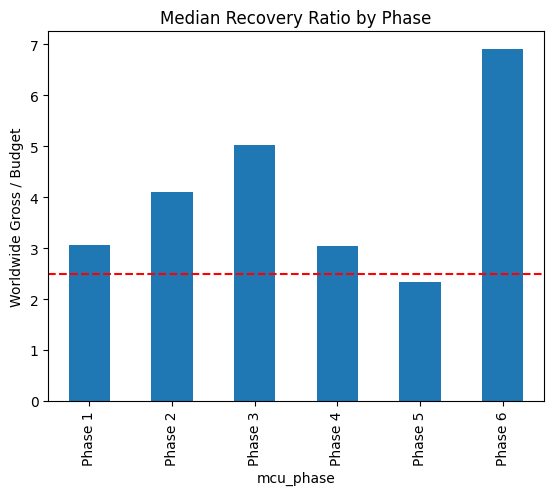

In [ ]:
import matplotlib.pyplot as plt

phase_summary['median'].plot(kind='bar', title='Median Recovery Ratio by Phase')
plt.axhline(y=2.5, color='r', linestyle='--')
plt.ylabel('Worldwide Gross / Budget')
plt.savefig('/content/drive/MyDrive/MCU_Case_Analysis/phase_recovery.png', dpi=200, bbox_inches='tight')
plt.show()

*Dashed line indicates the estimated 2.5x break-even threshold*


---

We can see a notable decline from Phase 3 going into Phase 4 (end of the **Infinity Saga** going into the **Multiverse Saga**), with Phase 5 continuing the trend until Phase 6, with Sony's *Spider-Man Brand New Day* being one of the biggest superhero box-office hits to date.
  - However Phase 6 only comprises of 2 films: *Brand New Day* and *Fantastic Four First Steps*.

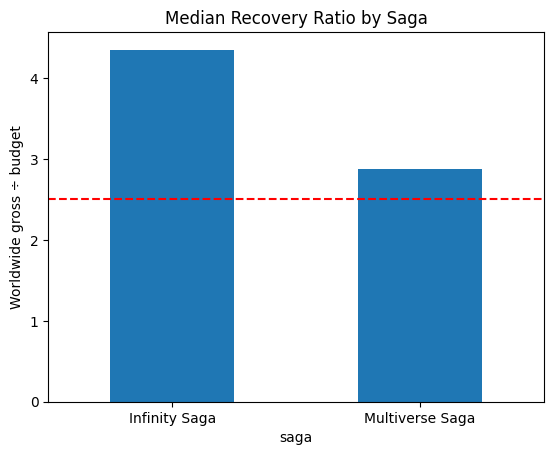

In [ ]:
saga_summary['median'].plot(kind='bar', title='Median Recovery Ratio by Saga', rot=0)
plt.axhline(2.5, color='red', linestyle='--')
plt.ylabel('Worldwide gross ÷ budget')
plt.savefig('/content/drive/MyDrive/MCU_Case_Analysis/saga_recovery.png', dpi=200, bbox_inches='tight')
plt.show()


*Dashed line indicates the estimated 2.5x break-even threshold*

---


When taking the same chart from earlier and looking at it from a Saga perspective, Multiverse's struggles become more apparent compared to Infinity Saga.
  - As mentioned earlier, the Multiverse Saga at this moment (November 15, 2026) is struggling to stay above the threshold.

## Objective B: Determining whether this is general "superhero fatigue" or are only certain projects underperforming?


In [ ]:
# "I am inevitable?" - Superhero Fatigue

For this section we need to label and define each film as either an **event** or **standard** release, then compare the two tiers across sagas on recovery, hit rate, and reception.

Definitions:
- **Event**: a film whose premise is a team-up of characters drawn from multiple MCU projects.
- **Standard** : solo films, sequels, new-character introductions. *Films with guest appearances from other franchises (ex: Iron Man in Spider-Man Homecoming, Hulk in Thor Ragnarok) are classified as Standard*

In [ ]:
# listing event films
event_titles = [
    'The Avengers', 'Avengers Age of Ultron',
    'Captain America Civil War', 'Avengers Infinity War',
    'Avengers Endgame', 'Spider-Man No Way Home',
    'Deadpool & Wolverine', 'Thunderbolts'
]

# safety check
missing = []
for t in event_titles:
  if t not in films['movie_title'].values:
    missing.append(t)
print('Titles not found', missing)

Titles not found []


In [ ]:
# we can list all other films as 'standard'
films['tier'] = 'standard'

films.loc[films['movie_title'].isin(event_titles), 'tier'] = 'event'

# print a count of total 'standard' vs 'event' films
films['tier'].value_counts()

,count
tier,
standard,30
event,8


In [ ]:
# now we can count films by saga and tier
films.groupby(by=['saga', 'tier'])['movie_title'].count()

saga             tier    
Infinity Saga    event        5
                 standard    18
Multiverse Saga  event        3
                 standard    12
Name: movie_title, dtype: int64

###Saga Performance

In [ ]:
tier_recovery = films.groupby(by=['saga', 'tier'])['recovery_ratio'].agg(['count', 'mean', 'median']).round(2)
tier_recovery

count  mean  median
saga            tier                         
Infinity Saga   event         5  5.90    6.32
                standard     18  4.44    4.19
Multiverse Saga event         3  6.14    6.69
                standard     12  3.37    2.74

In [ ]:
films.groupby(by=['saga', 'tier'])['below_2_5x'].sum()

saga             tier    
Infinity Saga    event       0
                 standard    1
Multiverse Saga  event       1
                 standard    5
Name: below_2_5x, dtype: int64

####Underperformers throughout both sagas

In [ ]:
cols = ['movie_title', 'saga', 'tier', 'recovery_ratio']

underperformers = films.loc[films['below_2_5x'] == True, cols].reset_index(drop=True)
underperformers

,movie_title,saga,tier,recovery_ratio
0,The Incredible Hulk,Infinity Saga,standard,1.93
1,Black Widow,Multiverse Saga,standard,1.90
2,Eternals,Multiverse Saga,standard,1.70
3,Ant-Man and the Wasp Quantumania,Multiverse Saga,standard,2.38
4,The Marvels,Multiverse Saga,standard,0.76
5,Captain America Brave New World,Multiverse Saga,standard,2.31
6,Thunderbolts,Multiverse Saga,event,2.12


Despite being an event film (could be disputed but using our definition established earlier, we will consider it an event film), *Thunderbolts* fell short of reaching the 2.5x threshold - marking it as the only underperforming event film.

####All Multiverse Standard films, ranked best to worst via recovery ratio

In [ ]:
multi = films[films['saga'] == 'Multiverse Saga']
multi_standard = multi[multi['tier'] == 'standard']
multi_standard[cols].sort_values(by='recovery_ratio', ascending=False).reset_index(drop=True)

,movie_title,saga,tier,recovery_ratio
0,Spider-Man Brand New Day,Multiverse Saga,standard,11.21
1,Doctor Strange in the Multiverse of Madness,Multiverse Saga,standard,4.78
2,Black Panther Wakanda Forever,Multiverse Saga,standard,3.44
3,Guardians of the Galaxy Vol. 3,Multiverse Saga,standard,3.38
4,Thor Love and Thunder,Multiverse Saga,standard,3.04
5,Shang-Chi and the Legend of the Ten Rings,Multiverse Saga,standard,2.88
6,The Fantastic Four First Steps,Multiverse Saga,standard,2.61
7,Ant-Man and the Wasp Quantumania,Multiverse Saga,standard,2.38
8,Captain America Brave New World,Multiverse Saga,standard,2.31
9,Black Widow,Multiverse Saga,standard,1.90


Spider-Man Brand New Day (11.21x) is an outlier, earning more than double the next-best Standard film. It is the main reason the group’s mean (3.37x) is well above its median (2.74x).

Sequels to established Infinity Saga franchises held up above the 2.5x threshold:
- Doctor Strange in the Multiverse of Madness: 4.78x
- Black Panther Wakanda Forever: 3.44x
- Guardians of the Galaxy Vol. 3: 3.38x
- Thor Love and Thunder: 3.04x

The Marvels (0.76x), the weakest film in the dataset, leaned heavily on viewers knowing its Disney+ series (Ms. Marvel, WandaVision).

Black Widow, Shang-Chi, and Eternals were released in 2021 during the pandemic recovery, and Black Widow also had a same-day release on Disney+ alongside its theatrical debut. **Their numbers should be read with that in mind.**

####Top 10 Overall MCU films based on recovery ratio

In [ ]:
# "I can do this all day." - Audiences going to MCU Event movies

In [ ]:
films[cols].sort_values(by='recovery_ratio', ascending=False).reset_index(drop=True).head(10)

,movie_title,saga,tier,recovery_ratio
0,Spider-Man Brand New Day,Multiverse Saga,standard,11.21
1,Spider-Man No Way Home,Multiverse Saga,event,9.61
2,Avengers Endgame,Infinity Saga,event,7.86
3,Spider-Man Far From Home,Infinity Saga,standard,7.07
4,The Avengers,Infinity Saga,event,6.90
5,Black Panther,Infinity Saga,standard,6.77
6,Deadpool & Wolverine,Multiverse Saga,event,6.69
7,Captain Marvel,Infinity Saga,standard,6.47
8,Avengers Infinity War,Infinity Saga,event,6.32
9,Iron Man 3,Infinity Saga,standard,6.07


Despite Event films taking up 8 out of the 38 film slots (21%), they account for half of the Top 10 spots.

The initial *Avengers* movie trumps the highly regarded *Avengers Infinity War* when considering the budget and revenue, while *Infinity War* did bring in over $2.05 billion to the box office compared to *The Avengers* (a 35% increase in revenue).

Sony’s Spider-Man films hold 3 of the top 4 spots, which supports the earlier finding that Spider-Man is propping up the Multiverse Saga’s numbers.

In the Infinity Saga, Standard films like Black Panther, Captain Marvel and Iron Man 3 reached the top tier. Multiverse Standard films have not, with the best (Doctor Strange in the Multiverse of Madness, 4.78x) falling well short of 10th place (6.07x)

###Saga Ratings

In [ ]:
tier_ratings = films.groupby(by=['saga', 'tier'])[['tomato_meter', 'audience_score']].mean().round(2)
tier_ratings

# Audience scores rose for both tiers,
# likely because only committed fans turn out for Standard films
# & Rotten Tomatoes moved to verified ratings in 2019.
# They’re treated as a weaker signal than critic scores here.

tomato_meter  audience_score
saga            tier                                  
Infinity Saga   event            87.20           88.60
                standard         83.94           80.61
Multiverse Saga event            86.00           94.00
                standard         70.83           86.67

####Top 10 MCU films by Critic Score

In [ ]:
rating_cols = ['movie_title', 'saga', 'tier', 'tomato_meter', 'audience_score']
films[rating_cols].sort_values(by='tomato_meter', ascending=False).reset_index(drop=True).head(10)

,movie_title,saga,tier,tomato_meter,audience_score
0,Black Panther,Infinity Saga,standard,96,79
1,Iron Man,Infinity Saga,standard,94,91
2,Avengers Endgame,Infinity Saga,event,94,90
3,Thor Ragnarok,Infinity Saga,standard,93,87
4,Spider-Man No Way Home,Multiverse Saga,event,93,97
5,Shang-Chi and the Legend of the Ten Rings,Multiverse Saga,standard,92,98
6,Spider-Man Homecoming,Infinity Saga,standard,92,87
7,The Avengers,Infinity Saga,event,91,91
8,Guardians of the Galaxy,Infinity Saga,standard,91,92
9,Spider-Man Far From Home,Infinity Saga,standard,91,95


Placing films based on critic scores, we can see that 8/10 films are Infinity Saga entries. This suggests critics rated earlier MCU films more highly.

*Shang-Chi* held strong scores but only reached a 2.88x recovery. Its 2021 pandemic-era release may have held it back.

####Bottom 10 Films by Critic Score (Bottom First)

In [ ]:
rating_cols = ['movie_title', 'saga', 'tier', 'tomato_meter', 'audience_score']
films[rating_cols].sort_values(by='tomato_meter', ascending=True).reset_index(drop=True).head(10)

,movie_title,saga,tier,tomato_meter,audience_score
0,Ant-Man and the Wasp Quantumania,Multiverse Saga,standard,46,82
1,Captain America Brave New World,Multiverse Saga,standard,46,75
2,Eternals,Multiverse Saga,standard,47,77
3,The Marvels,Multiverse Saga,standard,62,80
4,Thor Love and Thunder,Multiverse Saga,standard,63,76
5,Thor The Dark World,Infinity Saga,standard,66,75
6,The Incredible Hulk,Infinity Saga,standard,67,70
7,Iron Man 2,Infinity Saga,standard,72,71
8,Doctor Strange in the Multiverse of Madness,Multiverse Saga,standard,73,85
9,Avengers Age of Ultron,Infinity Saga,event,76,82


###Median Recovery: Event vs Standard Chart

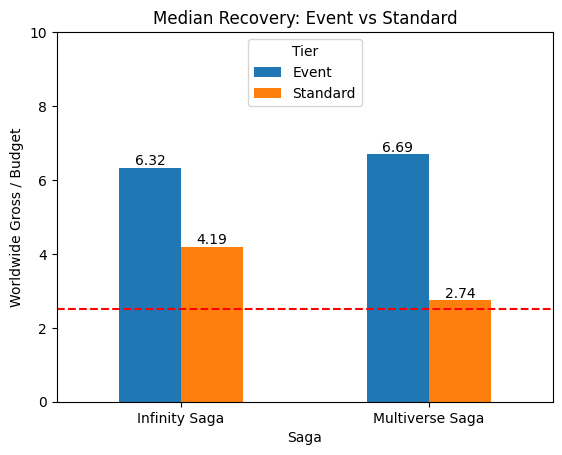

In [ ]:
ax = tier_recovery['median'].unstack().plot(kind='bar', title='Median Recovery: Event vs Standard', rot=0)
plt.legend(title='Tier', labels=['Event', 'Standard'], loc='upper center')
plt.axhline(y=2.5, color='r', linestyle='--')
plt.ylabel('Worldwide Gross / Budget')
plt.xlabel("Saga")

plt.ylim(0, 10)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.2f')
plt.savefig('/content/drive/MyDrive/MCU_Case_Analysis/tier_recovery.png', dpi=200, bbox_inches='tight')
plt.show()

*Dashed line indicates the estimated 2.5x break-even threshold*


---

The Median Recovery chart tells us a few things:
- Event films held steady across the two sagas, where the median recovery increased from 6.32x to 6.69x.

- Standard films however fell about 35%, going from 4.19x to 2.74x, sitting just above the break-even point.

- Underperformers are concentrated in the Standard films, where 5/12 Multiverse movies fell short compared to the 1/18 benchmark seen throughout Infinity Saga films.



###Average Tomato Meter: Event vs Standard Chart

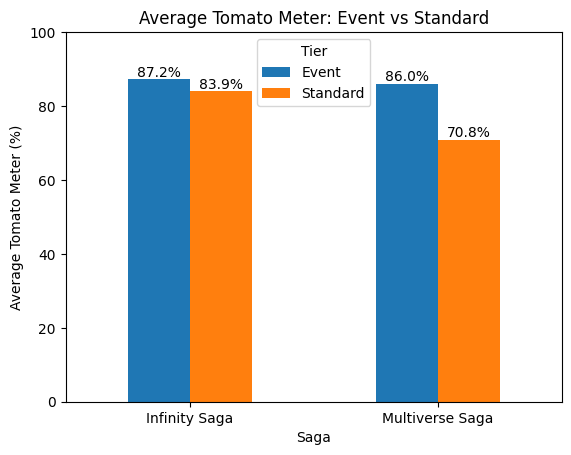

In [ ]:
ax = tier_ratings['tomato_meter'].unstack().plot(kind='bar', title='Average Tomato Meter: Event vs Standard', rot=0)
plt.ylabel('Average Tomato Meter (%)')
plt.xlabel("Saga")
plt.ylim(0, 100)
plt.legend(title='Tier', labels=['Event', 'Standard'], loc='upper center')

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.1f%%')
plt.savefig('/content/drive/MyDrive/MCU_Case_Analysis/tier_ratings.png', dpi=200, bbox_inches='tight')
plt.show()

When looking at the performances and scores across the MCU’s projects, the evidence suggests there is no broad “superhero fatigue” plaguing Disney’s flagship franchise. Event films continue to perform well at the box office and with critics. The decline is concentrated in Standard releases, with a few standout successes as the exception.
- *Spider-Man Brand New Day* (11.21x) is a Standard release, yet it has had one of the biggest box office runs in superhero history (as of November 18, 2026). Audiences still show up in huge numbers for characters they’re invested in. Note that it is a Sony co-production (as is Event film No Way Home), so its success says more about Spider-Man’s appeal than about Marvel Studios’ own slate.
- The one Event underperformer, *Thunderbolts* (2.12x), was built around lesser-known characters, which suggests crossovers draw event-sized crowds only when they feature headliners, though the film did garner favorable critic reviews (88% on Rotten Tomatoes).

***Caveat: the Multiverse Saga has only 3 Event films so far, so the Event-tier comparison is directional.***

# Objective C: Disney+ output vs. theatrical performance


This objective seeks to answer whether Marvel's increase in Disney+ series output (starting in 2021) had an influence in a weaker box office for its films.

In [ ]:
# we will begin by counting how many projects came out each year
# split by type (film / series)
output_by_year = df.groupby(by=['year', 'type']).size()
output_by_year = output_by_year.unstack(fill_value=0)
output_by_year

type,film,series
year,,
2008,2,0
2010,1,0
2011,2,0
2012,1,0
2013,2,0
2014,2,0
2015,2,0
2016,2,0
2017,3,0


In [ ]:
film_recovery_by_year = films.groupby(by='year')['recovery_ratio'].median().round(2)
film_recovery_by_year

,recovery_ratio
year,
2008,3.06
2010,3.11
2011,2.82
2012,6.90
2013,4.93
2014,4.38
2015,3.90
2016,4.36
2017,4.75


In [ ]:
# combining output and film recovery side by side
year_summary = output_by_year.copy()
year_summary['total'] = year_summary['film'] + year_summary['series']
year_summary['recovery_ratio'] = film_recovery_by_year
year_summary

type,film,series,total,recovery_ratio
year,,,,
2008,2,0,2,3.06
2010,1,0,1,3.11
2011,2,0,2,2.82
2012,1,0,1,6.90
2013,2,0,2,4.93
2014,2,0,2,4.38
2015,2,0,2,3.90
2016,2,0,2,4.36
2017,3,0,3,4.75


## MCU Project Output & Recovery Charts

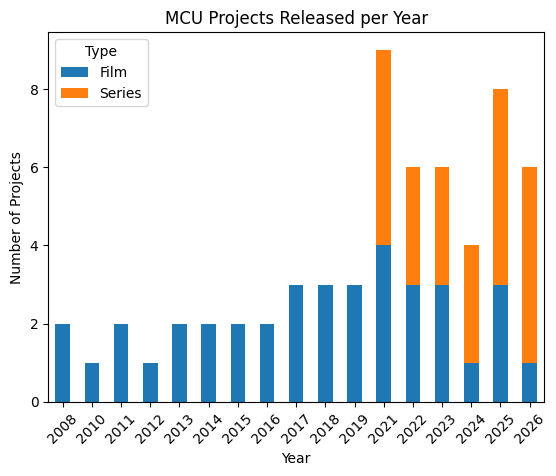

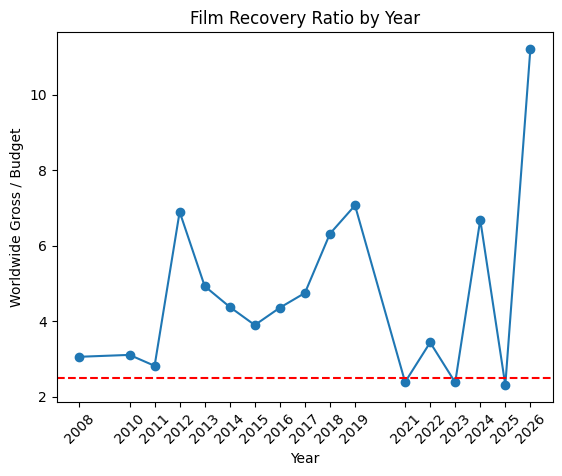

In [ ]:
output_by_year.plot(kind='bar', stacked=True, title='MCU Projects Released per Year', rot=45)
plt.xlabel('Year')
plt.ylabel('Number of Projects')
plt.legend(title='Type', labels=['Film', 'Series'])
plt.savefig('/content/drive/MyDrive/MCU_Case_Analysis/output_by_year.png', dpi=200, bbox_inches='tight')
plt.show()

film_recovery_by_year.plot(kind='line', marker='o', title='Film Recovery Ratio by Year')
plt.axhline(y=2.5, color='r', linestyle='--')
plt.ylabel('Worldwide Gross / Budget')
plt.xlabel('Year')
plt.xticks(film_recovery_by_year.index, rotation=45)
plt.savefig('/content/drive/MyDrive/MCU_Case_Analysis/recovery_by_year.png', dpi=200, bbox_inches='tight')
plt.show()


*Dashed line indicates the estimated 2.5x break-even threshold.*

*No MCU projects released in 2009 or 2020.*



---

MCU's output more than doubled at 2021 when Disney+ series began, raising the average projects per year from 2 to about 6.5.

2008-2019 saw consistent film performance (steady recovery ratios well above the 2.5x threshold), but 3 of the 6 years since the Disney+ surge saw the median fall below this critical threshold, including two of the busiest years on record (2021, 2025).

The strong recent years were each carried by a single headline movie release, each the only MCU film released that year.
  - *Deadpool & Wolverine* (2024)
  - *Spider-Man Brand New Day* (2026)

---
The yearly charts show output and returns moving together, but not why. This doesn’t prove the extra content caused the decline. The same period also included the pandemic, shorter theatrical windows, and the end of the Infinity Saga storyline. To look more directly, we compared Multiverse films that rely on a Disney+ series against those that stand alone.




##Tired of Homework?
Breaking down the performance of films dependent on their viewers watching Disney+ series to fully understand context.

In [ ]:
# Multiverse films whose main story is reliant on Disney+ series context
series_dependent = [
    'The Marvels', 'Thunderbolts', 'Captain America Brave New World',
    'Doctor Strange in the Multiverse of Madness'
]

multi_series = films[films['saga'] == 'Multiverse Saga'].copy()

multi_series['needs_series'] = multi_series['movie_title'].isin(series_dependent)

In [ ]:
series_summary = multi_series.groupby(by='needs_series')['recovery_ratio'].agg(['count', 'mean', 'median']).round(2)
series_summary['below_2_5x'] = multi_series.groupby(by='needs_series')['below_2_5x'].sum()
series_summary.index = ['Stands alone', 'Needs a series']
series_summary

,count,mean,median,below_2_5x
Stands alone,11,4.44,3.04,3
Needs a series,4,2.49,2.22,3


Multiverse films that rely on Disney+ series earned a median of 2.22x, falling short of the 2.5x threshold compared to the 3.04x median for films that stand alone, with 3/4 of these "homework" films placing below the break-even point.

Combined with Objective B, the evidence points to a specific problem rather than a genre-spanning issue:
- Event films with headliner characters still perform strongly.
  - 6.69x median with Event Multiverse Saga films, up from 6.32x with Event Infinity Saga films.

- Standard films have fell about 35%, from a median of 4.19x to 2.74x, and 5 of 12 Multiverse Standard films missed break-even, compared with 1 of 18 in the Infinity Saga.

- Films that require Disney+ “homework” performed worst of all. At a 2.22x median, they’re the only group whose typical film fails to break even.

This suggests audiences have not tired of the MCU but have become more selective: the films that leaned most on Disney+ series performed worst, which is consistent with casual viewers passing on films that feel like required viewing.

---
***Caveat: the series-dependent films only contains 4 films as of this moment.***


In [ ]:
# Avengers, assemble." - sending notebook to Tableau for data presentation.
films['needs_series'] = films['movie_title'].isin(series_dependent)
films.to_csv('/content/drive/MyDrive/MCU_Case_Analysis/06_Tableau_Data/mcu_tableau.csv', index=False)
